# Pure B-spline Kalman filter — dynamic smile with N basis functions

**Motivation:** Replace the SVI backbone entirely.  Represent the implied-vol smile as a
linear combination of cubic B-spline basis functions with **fixed knots** in log-moneyness:

$$\text{IV}(k,\,t) = \sum_{i=1}^{N} \beta_i(t)\,B_i(k)$$

Because $\{B_i\}$ form a *partition of unity* the observation model is **linear** in $\beta$,
so we use a standard (non-extended) Kalman filter — exact inference, no linearisation error.

| Component | Dim | Role |
|-----------|-----|------|
| $\beta$ (B-spline weights) | ~25 | Full smile in IV units |
| **Total state** | **~25** | One vector, updated on every quote tick |

In [2]:
import importlib as imp
import os
import sys
from datetime import date, datetime

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
from plotly.subplots import make_subplots
from scipy.interpolate import BSpline

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)
sys.path.insert(0, os.path.dirname(os.path.abspath("__file__")))

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"
os.environ["QUANTDATA_TRAINING_DATA"] = "!/quantdata/training"
os.environ["QUANTDATA_PROCESSING_DATA"] = "!/quantdata/processing"
os.environ["QUANTDATA_CACHE_MODE"] = "on"
os.environ["QUANTDATA_TEST_MODE"] = "0"

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

import surface_kalman_filters
import surface_model

import personal.shared_functions.kalman_filters as kalman_filters
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## Config — pure B-spline basis

In [53]:
# ── B-spline geometry ──────────────────────────────────────────────────────────
N_BASIS = 20  # number of cubic B-spline basis functions
K_MIN = -0.05  # left boundary in log-moneyness
K_MAX = 0.05  # right boundary
DEGREE = 3  # cubic splines

# ── Kalman noise parameters ────────────────────────────────────────────────────
Q_SCALE = 5e-5  # process noise per step (controls tracking speed)
P0_SCALE = 0.01  # initial state uncertainty (large → converges fast)
BETA_INIT = 0.12  # flat-smile initialisation: β·B(k) = BETA_INIT ∀k
# (partition-of-unity property ensures this)

# ── Build clamped knot vector ─────────────────────────────────────────────────
_n_interior = N_BASIS - DEGREE - 1
_interior = np.linspace(K_MIN, K_MAX, _n_interior + 2)[1:-1]
bspline_knots = np.r_[
    np.repeat(K_MIN, DEGREE + 1),
    _interior,
    np.repeat(K_MAX, DEGREE + 1),
]
bspline_interior_knots = _interior
bspline_klo = float(bspline_knots[DEGREE])
bspline_khi = float(bspline_knots[-(DEGREE + 1)])

# Greville abscissae — interpretable "centre of mass" for each basis function
greville = np.array([bspline_knots[i + 1 : i + DEGREE + 1].mean() for i in range(N_BASIS)])

print(f"N_BASIS={N_BASIS}, DEGREE={DEGREE}, n_interior={_n_interior}")
print(f"Knot vector length : {len(bspline_knots)}")
print(f"Domain             : [{bspline_klo:.3f}, {bspline_khi:.3f}]")
print(f"Interior knot spacing: {(_interior[1] - _interior[0]):.4f} in log-moneyness")
print(f"Q_SCALE={Q_SCALE}, P0_SCALE={P0_SCALE}, BETA_INIT={BETA_INIT}")

N_BASIS=20, DEGREE=3, n_interior=16
Knot vector length : 24
Domain             : [-0.050, 0.050]
Interior knot spacing: 0.0059 in log-moneyness
Q_SCALE=5e-05, P0_SCALE=0.01, BETA_INIT=0.12


## Basis function visualisation

Shows all 25 cubic B-spline basis functions over the log-moneyness domain.
Each $B_i$ has local support (~4 knot spans); they sum to 1 everywhere (partition of unity).

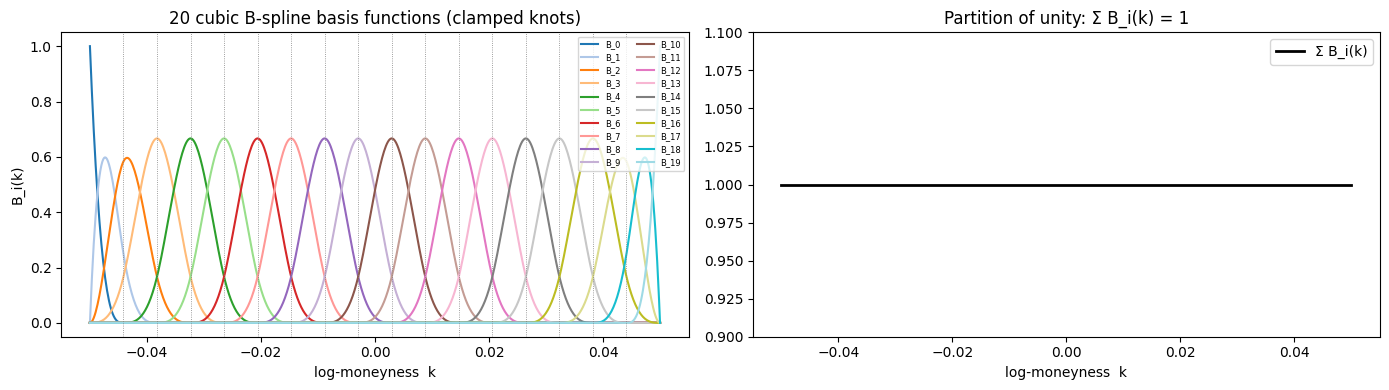

Sum of basis at ATM (k=0): 1.00000000


In [54]:
k_vis = np.linspace(K_MIN, K_MAX, 600)
k_vis_clamped = np.clip(k_vis, bspline_klo, bspline_khi)
Phi_vis = BSpline.design_matrix(k_vis_clamped, bspline_knots, DEGREE).toarray()  # (600, N_BASIS)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: all basis functions
cmap = plt.cm.tab20
for i in range(N_BASIS):
    axes[0].plot(k_vis, Phi_vis[:, i], color=cmap(i / N_BASIS), lw=1.5, label=f"B_{i}")
for kk in bspline_interior_knots:
    axes[0].axvline(kk, color="grey", lw=0.6, ls=":")
axes[0].set_title(f"{N_BASIS} cubic B-spline basis functions (clamped knots)")
axes[0].set_xlabel("log-moneyness  k")
axes[0].set_ylabel("B_i(k)")
axes[0].legend(loc="upper right", fontsize=6, ncol=2)

# Right: partition of unity check
axes[1].plot(k_vis, Phi_vis.sum(axis=1), "k-", lw=2, label="Σ B_i(k)")
axes[1].set_ylim(0.9, 1.1)
axes[1].set_title("Partition of unity: Σ B_i(k) = 1")
axes[1].set_xlabel("log-moneyness  k")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Sum of basis at ATM (k=0): {Phi_vis[np.abs(k_vis).argmin()].sum():.8f}")

## Data loading

In [55]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [56]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

## Build IV observation stream

In [57]:
imp.reload(surface_kalman_filters)

df_quotes_iv, df_trades_iv = surface_kalman_filters.build_iv_observations(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
    simple=False,
)
print(f"Quotes: {df_quotes_iv.shape[0]:,} rows, {df_quotes_iv['strike'].n_unique()} strikes")
print(f"Trades: {df_trades_iv.shape[0]:,} rows")
df_quotes_iv.head()

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
Quotes: 2,115,510 rows, 25 strikes
Trades: 74,099 rows


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43


In [58]:
# OTM filter: keep puts (k < 0) and calls (k ≥ 0) only.
df_quotes_otm = df_quotes_iv.filter(
    (pl.col("is_call") & (pl.col("log_moneyness") >= 0))
    | (~pl.col("is_call") & (pl.col("log_moneyness") < 0))
)
print(f"Quotes before OTM filter: {df_quotes_iv.shape[0]:,}  →  after: {df_quotes_otm.shape[0]:,}")

Quotes before OTM filter: 2,115,510  →  after: 978,523


In [59]:
# small cheating to better clip the k-grid to the observed strikes (instead of K_MIN/K_MAX)
k_min_obs = df_quotes_otm["log_moneyness"].min()
k_max_obs = df_quotes_otm["log_moneyness"].max()

In [60]:
k_min_idx = np.argmin(df_quotes_otm["log_moneyness"])

In [61]:
k_min_idx

np.int64(735213)

In [62]:
k_min_obs, k_max_obs

(-0.04652304593333177, 0.024092379010772404)

## Pure B-spline Kalman filter — implementation

**State**: $\beta \in \mathbb{R}^{N}$

**Observation**: $h(\beta,\,k) = \beta \cdot B(k)$ — *linear* in $\beta$

**Jacobian**: $H = B(k)$ — row vector of basis values at $k$

Since the model is linear we use the **standard Kalman filter** (not EKF):
$$\beta_{t|t} = \beta_{t|t-1} + K_t\bigl(z_t - H_t\,\beta_{t|t-1}\bigr),
\\ 
 \qquad
K_t = P_{t|t-1}\,H_t^\top \bigl(H_t\,P_{t|t-1}\,H_t^\top + R_t\bigr)^{-1}$$

In [63]:
def _kf_step(
    state: np.ndarray,
    P: np.ndarray,
    H: np.ndarray,
    z_hat: float,
    z: float,
    R: float,
    Q: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """One Kalman predict+update step with a scalar observation."""
    P_pred = P + Q
    innov = z - z_hat
    S = float(H @ P_pred @ H) + R
    K = (P_pred @ H) / S
    state_new = state + K * innov
    P_new = P_pred - np.outer(K, H) @ P_pred
    P_new = (P_new + P_new.T) * 0.5  # symmetrise
    return state_new, P_new


def _bspline_basis_row(
    k: float,
    knots: np.ndarray,
    degree: int,
    klo: float,
    khi: float,
) -> np.ndarray:
    """Evaluate all basis functions at a single log-moneyness k (clamped)."""
    k_c = float(np.clip(k, klo, khi))
    return BSpline.design_matrix([k_c], knots, degree).toarray()[0]


def run_bspline_only_kalman(
    df_quotes_iv: pl.DataFrame,
    df_trades_iv: pl.DataFrame,
    knots: np.ndarray,
    degree: int,
    klo: float,
    khi: float,
    n_basis: int,
    Q_scale: float = 5e-5,
    P0_scale: float = 0.01,
    beta_init: float = 0.12,
) -> tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame]:
    """
    Pure B-spline Kalman filter on implied volatility.

    State       : beta in R^n_basis
    Observation : h(beta, k) = beta · B(k)    [linear — standard KF]
    Jacobian    : H = B(k)

    Returns
    -------
    df_quotes_result : quotes + 'bspline_iv' column
    df_trades_result : trades + 'bspline_matched', 'trade_residual'
    df_state         : state history (columns ts_ns, state_0 … state_{n-1})
    """
    # Partition of unity: all beta_i = beta_init → IV(k) = beta_init ∀k
    state = np.full(n_basis, beta_init)
    Q = Q_scale * np.eye(n_basis)
    P = P0_scale * np.eye(n_basis)

    df_q = df_quotes_iv.sort("ts_ns")
    n_q = len(df_q)
    ks = df_q["log_moneyness"].to_numpy(allow_copy=True).astype(float)
    obs_ivs = df_q["observed_iv"].to_numpy(allow_copy=True).astype(float)
    Rs = df_q["R_iv"].to_numpy(allow_copy=True).astype(float)

    bspline_ivs = np.full(n_q, np.nan)
    states_hist = np.full((n_q, n_basis), np.nan)

    for i in range(n_q):
        H = _bspline_basis_row(ks[i], knots, degree, klo, khi)
        z_hat = float(state @ H)

        if np.isfinite(obs_ivs[i]) and np.isfinite(Rs[i]) and Rs[i] > 0 and np.isfinite(H).all():
            state, P = _kf_step(state, P, H, z_hat, obs_ivs[i], Rs[i], Q)
        else:
            P = P + Q

        bspline_ivs[i] = float(state @ H)
        states_hist[i] = state

    df_quotes_result = df_q.with_columns(pl.Series("bspline_iv", bspline_ivs.tolist()))

    # State history — one row per quote tick
    th_cols = {f"_st{j}": states_hist[:, j].tolist() for j in range(n_basis)}
    df_state = pl.DataFrame({"ts_ns": df_q["ts_ns"], **th_cols})
    df_state_out = df_state.rename({f"_st{j}": f"state_{j}" for j in range(n_basis)})

    if df_trades_iv.is_empty() or "quote_ts_ns" not in df_trades_iv.columns:
        return df_quotes_result, df_trades_iv, df_state_out

    # Match each trade to the most-recent Kalman state
    df_t = df_trades_iv.sort("quote_ts_ns").join_asof(
        df_state, left_on="quote_ts_ns", right_on="ts_ns", strategy="backward"
    )
    t_ks = df_t["log_moneyness"].to_numpy(allow_copy=True).astype(float)
    st_t = np.column_stack([df_t[f"_st{j}"].to_numpy(allow_copy=True) for j in range(n_basis)])

    n_t = len(df_t)
    bspline_matched = np.full(n_t, np.nan)

    for i in range(n_t):
        if np.isfinite(st_t[i]).all() and np.isfinite(t_ks[i]):
            H = _bspline_basis_row(t_ks[i], knots, degree, klo, khi)
            bspline_matched[i] = float(st_t[i] @ H)

    drop_cols = [f"_st{j}" for j in range(n_basis)]
    df_trades_result = (
        df_t.with_columns(pl.Series("bspline_matched", bspline_matched.tolist()))
        .with_columns((pl.col("observed_iv") - pl.col("bspline_matched")).alias("trade_residual"))
        .drop(drop_cols)
    )

    return df_quotes_result, df_trades_result, df_state_out

## Run the B-spline-only filter

In [64]:
df_quotes_bs, df_trades_bs, df_state_bs = run_bspline_only_kalman(
    df_quotes_iv=df_quotes_otm,
    df_trades_iv=df_trades_iv,
    knots=bspline_knots,
    degree=DEGREE,
    klo=bspline_klo,
    khi=bspline_khi,
    n_basis=N_BASIS,
    Q_scale=Q_SCALE,
    P0_scale=P0_SCALE,
    beta_init=BETA_INIT,
)
print(f"Quotes result : {df_quotes_bs.shape[0]:,} rows, cols: {df_quotes_bs.columns}")
print(f"Trades result : {df_trades_bs.shape[0]:,} rows")
df_quotes_bs.head()

Quotes result : 978,523 rows, cols: ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'bspline_iv']
Trades result : 74,099 rows


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,bspline_iv
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,0.136923
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,0.137437
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,0.138342
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,0.137874
2024-01-03 09:30:00.008504576 EST,466.0,false,-0.009462,0.006217,0.141883,0.140865,0.142848,9.8379e-7,0.57,0.59,470.43,0.141879


## Quick residual check

In [65]:
df_trades_clean = df_trades_bs.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_bs = float((df_trades_clean["trade_residual"] ** 2).mean() ** 0.5)
print(f"B-spline-only filter trade RMSE (IV): {rmse_bs * 100:.5f}%")
print(f"Clean trade rows: {df_trades_clean.shape[0]:,}")

B-spline-only filter trade RMSE (IV): 0.43646%
Clean trade rows: 74,099


## Smile snapshot — fitted B-spline at a point in time

Shows the Kalman-filtered smile $\hat{\text{IV}}(k) = \beta(t)\cdot B(k)$ against
market mid-IVs, along with each basis function's contribution $\beta_i \cdot B_i(k)$.

In [80]:
# ── Pick snapshot time (midday) ────────────────────────────────────────────────
row_idx = df_quotes_bs.shape[0] // 2
row_idx = int(k_min_idx)
snapshot_ts = df_quotes_bs["ts_ns"][row_idx]

state_row = df_state_bs.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
beta_snap = np.array([state_row[f"state_{j}"][0] for j in range(N_BASIS)])

snap_quotes = (
    df_quotes_bs.filter(pl.col("ts_ns") <= snapshot_ts).group_by(["strike", "is_call"]).last()
)

# Evaluate B-spline on dense k-grid
k_grid = np.linspace(K_MIN, K_MAX, 500)
k_grid_cl = np.clip(k_grid, bspline_klo, bspline_khi)
Phi_grid = BSpline.design_matrix(k_grid_cl, bspline_knots, DEGREE).toarray()
bspline_grid = Phi_grid @ beta_snap  # total B-spline IV
contrib_grid = Phi_grid * beta_snap[None, :]  # each basis' contribution

# ── Plot ──────────────────────────────────────────────────────────────────────
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    row_heights=[0.65, 0.35],
    vertical_spacing=0.05,
    subplot_titles=["Implied vol smile", "Basis-function contributions β_i · B_i(k)"],
)

# Market quotes
for is_c, label, color in [(True, "calls", "royalblue"), (False, "puts", "firebrick")]:
    sq = snap_quotes.filter(pl.col("is_call") == is_c)
    fig.add_trace(
        go.Scatter(
            x=sq["log_moneyness"].to_list(),
            y=sq["observed_iv"].to_list(),
            mode="markers",
            marker=dict(color=color, symbol="x", size=8),
            name=f"{label} — market",
        ),
        row=1,
        col=1,
    )

# Fitted B-spline
fig.add_trace(
    go.Scatter(
        x=k_grid.tolist(),
        y=bspline_grid.tolist(),
        mode="lines",
        line=dict(color="crimson", width=2.5),
        name="B-spline fit β·B(k)",
    ),
    row=1,
    col=1,
)

# Individual contributions (stacked area)
cmap = plt.cm.tab20
for i in range(N_BASIS):
    fig.add_trace(
        go.Scatter(
            x=k_grid.tolist(),
            y=contrib_grid[:, i].tolist(),
            mode="lines",
            line=dict(
                color=f"rgba{tuple(int(c * 255) for c in cmap(i / N_BASIS)[:3]) + (0.6,)}", width=1
            ),
            name=f"β_{i}·B_{i}  (ξ={greville[i]:+.3f})",
            showlegend=False,
        ),
        row=2,
        col=1,
    )

fig.add_hline(y=0, line=dict(color="black", width=1, dash="dash"), row=2, col=1)
for kk in bspline_interior_knots:
    fig.add_vline(x=kk, line=dict(color="grey", width=0.6, dash="dot"))

fig.update_layout(
    title=f"B-spline-only filter snapshot  |  ts={snapshot_ts}",
    height=650,
    legend=dict(x=0.75, y=0.98),
)
fig.update_yaxes(title_text="Implied vol", row=1, col=1)
fig.update_yaxes(title_text="IV contribution", row=2, col=1)
fig.update_xaxes(title_text="log-moneyness  k = log(K/F)", row=2, col=1)
fig.show()

print(f"ATM IV (k≈0): {float(Phi_grid[np.abs(k_grid).argmin()] @ beta_snap):.5f}")
print(f"β range: [{beta_snap.min():.5f}, {beta_snap.max():.5f}]")

ATM IV (k≈0): 0.13191
β range: [-0.07439, 0.36817]


## β(t) evolution — intraday dynamics of the B-spline weights

Each line is one weight $\beta_i(t)$, labelled by its Greville abscissa $\xi_i$ (centre of support).
Drift in these weights reveals how the smile shape evolves through the trading day.

In [67]:
# Sub-sample for plotting (every 500th quote)
df_state_sub = df_state_bs[::500]
ts_plot = df_state_sub["ts_ns"].to_list()

cmap20 = plt.cm.tab20

fig = go.Figure()
for i in range(N_BASIS):
    beta_i = df_state_sub[f"state_{i}"].to_numpy()
    r, g, b, _ = cmap20(i / N_BASIS)
    color = f"rgb({int(r * 255)},{int(g * 255)},{int(b * 255)})"
    fig.add_trace(
        go.Scatter(
            x=ts_plot,
            y=beta_i.tolist(),
            mode="lines",
            name=f"β_{i}  (ξ={greville[i]:+.3f})",
            line=dict(color=color, width=1.5),
        )
    )

fig.add_hline(y=0, line=dict(color="black", width=1, dash="dash"))
fig.update_layout(
    title="B-spline weights β_i(t) — intraday evolution",
    xaxis_title="Time",
    yaxis_title="β_i  (IV units)",
    height=450,
    legend=dict(x=1.01, y=1.0),
)
fig.show()

## Smile surface over the trading day

Heatmap of the fitted smile $\hat{\text{IV}}(k, t) = \beta(t)\cdot B(k)$,
showing how the level and shape evolve intraday.

In [68]:
# # Sub-sample and build smile surface matrix
# STEP = 1000  # every STEP-th quote row
# df_surf = df_state_bs[::STEP]
# ts_surf = df_surf["ts_ns"].to_list()

# k_surf = np.linspace(K_MIN, K_MAX, 200)
# k_surf_cl = np.clip(k_surf, bspline_klo, bspline_khi)
# Phi_surf = BSpline.design_matrix(k_surf_cl, bspline_knots, DEGREE).toarray()

# beta_mat = np.column_stack(
#     [df_surf[f"state_{i}"].to_numpy() for i in range(N_BASIS)]
# )  # (n_steps, N_BASIS)
# iv_surface = beta_mat @ Phi_surf.T  # (n_steps, 200)

# fig = go.Figure(
#     go.Heatmap(
#         x=k_surf.tolist(),
#         y=[str(t)[:19] for t in ts_surf],
#         z=iv_surface.tolist(),
#         colorscale="RdYlGn_r",
#         colorbar=dict(title="IV"),
#     )
# )
# fig.update_layout(
#     title="Kalman-filtered IV smile surface — B-spline model (intraday)",
#     xaxis_title="log-moneyness  k = log(K/F)",
#     yaxis_title="Time",
#     height=500,
# )
# fig.show()

## Full evaluation

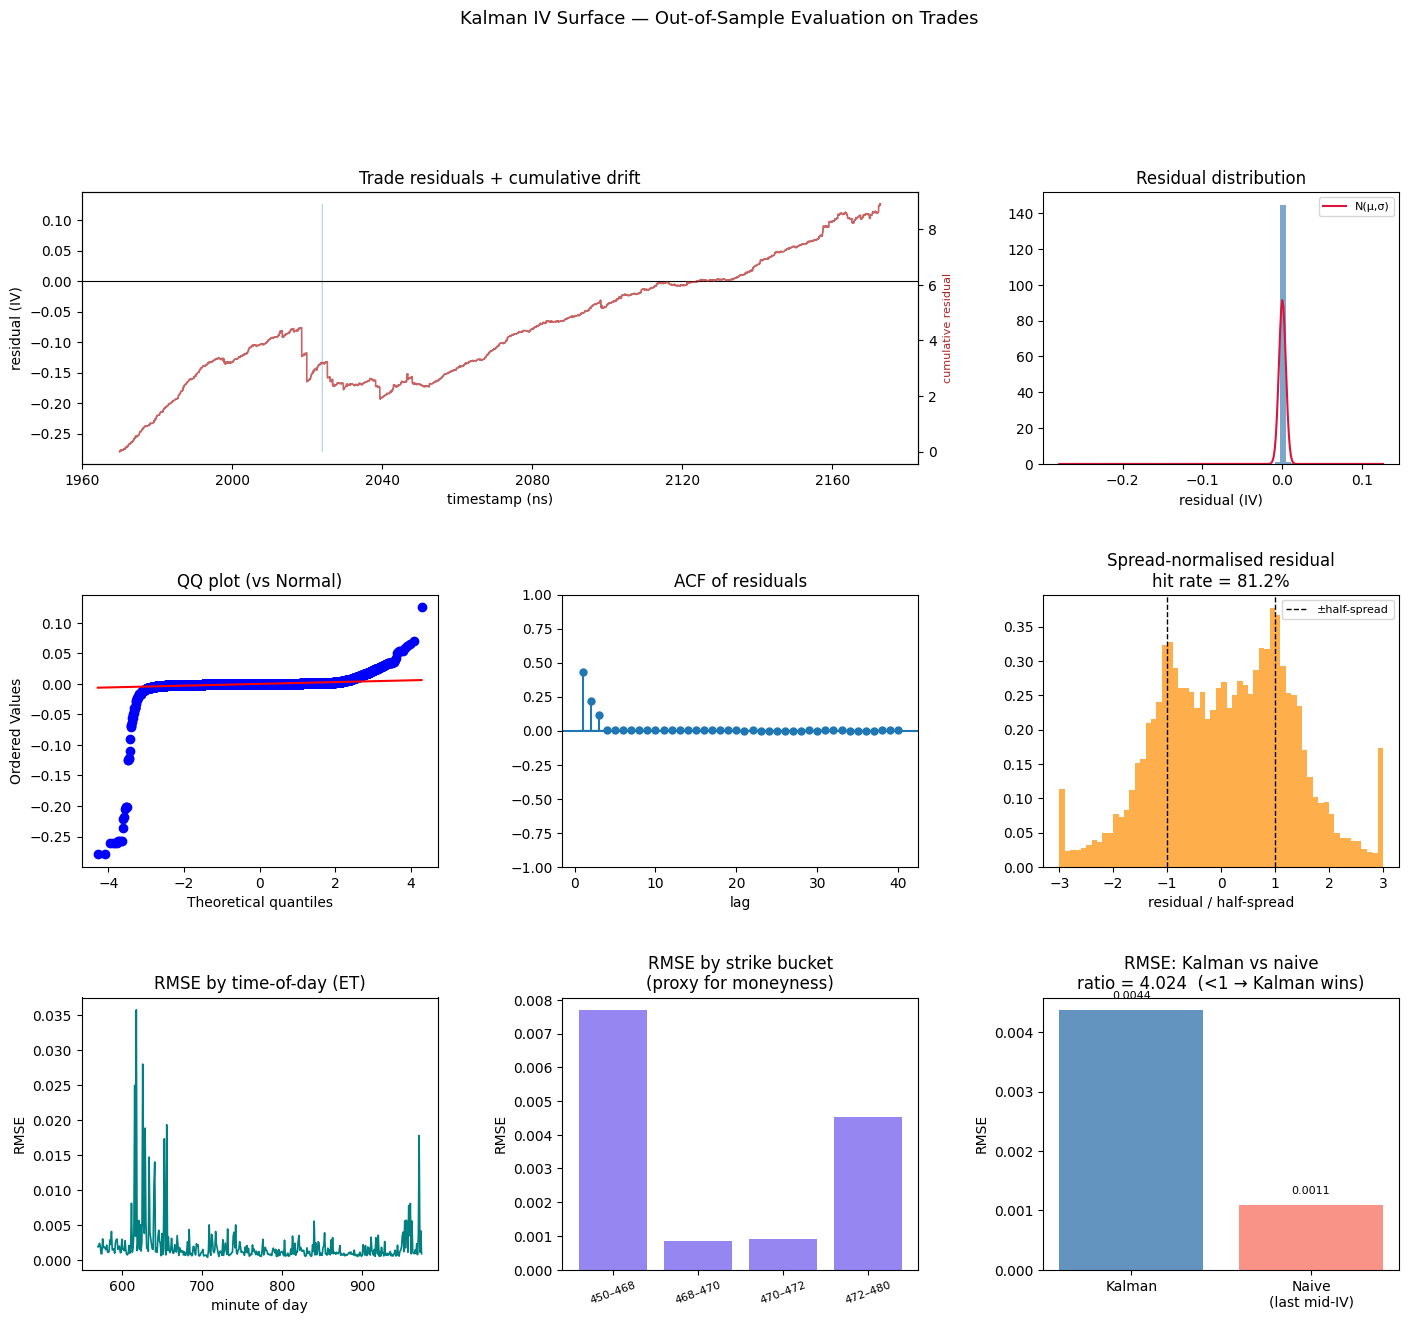

RMSE                 0.00436
MAE                  0.00080
Bias                 0.00012
Hit rate             81.2%
Naive RMSE           0.00108
RMSE ratio           4.024  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
         lb_stat  lb_pvalue
10  18294.490274        0.0
20  18307.426317        0.0


In [69]:
metrics_bs = evaluate_kalman_iv(
    df_quotes_iv=df_quotes_bs.rename({"bspline_iv": "kalman_iv"}),
    df_trades_iv=df_trades_bs.rename({"bspline_matched": "kalman_matched"}),
)

## Benchmark — B-spline-only vs SVI-only vs individual per-option KF

In [70]:
from surface_model import SVI_SLICE_MODEL, SurfaceModelConfig

svi_cfg = SurfaceModelConfig(
    model=SVI_SLICE_MODEL,
    Q_scale=0.05,
    Q_structure="scaled_identity",
    P0_scale=1.0,
)

# SVI-only Kalman
df_quotes_svi, df_trades_svi, _ = surface_kalman_filters.run_spline_surface_kalman(
    df_quotes_iv=df_quotes_otm,
    df_trades_iv=df_trades_iv,
    cfg=svi_cfg,
)
df_trades_svi_clean = df_trades_svi.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_svi = float((df_trades_svi_clean["trade_residual"] ** 2).mean() ** 0.5)

# Individual per-option KF
df_quotes_indiv, df_trades_indiv = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)
df_trades_indiv_clean = df_trades_indiv.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_indiv = float((df_trades_indiv_clean["trade_residual"] ** 2).mean() ** 0.5)

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000: dropping 64 bad quotes (sub-tick bid×64 (first=2024-01-03 10:00:01.421753-05:00))
O:SPY240105C00483000: dropping 842 bad quotes (sub-tick bid×842 (first=2024-01-03 09:30:00.060278-05:00), zero bid size×1 (first=2024-01-03 09:30:00.060278-05:00))
O:SPY240105C00484000: dropping 2129 bad quotes

In [71]:
label_bs = f"B-spline-only ({N_BASIS} params)"
print(f"{'Model':<42} {'RMSE (IV)':>12}   {'vs SVI-only':>12}")
print("-" * 70)
print(f"{'Individual per-option KF  (ceiling)':<42} {rmse_indiv:>12.5f}   {'—':>12}")
print(f"{'SVI-only Kalman           (baseline)':<42} {rmse_svi:>12.5f}   {'—':>12}")
print(f"{label_bs:<42} {rmse_bs:>12.5f}   {(rmse_bs / rmse_svi - 1) * 100:>+11.1f}%")
print()
print(f"B-spline vs individual KF  : {rmse_bs / rmse_indiv:.3f}  (<1.00 → B-spline wins)")
print(
    f"Gap closure vs SVI baseline: {(rmse_svi - rmse_bs) / (rmse_svi - rmse_indiv) * 100:.1f}% of SVI→indiv gap recovered"
)

Model                                         RMSE (IV)    vs SVI-only
----------------------------------------------------------------------
Individual per-option KF  (ceiling)             0.00274              —
SVI-only Kalman           (baseline)            0.00362              —
B-spline-only (20 params)                       0.00436         +20.5%

B-spline vs individual KF  : 1.591  (<1.00 → B-spline wins)
Gap closure vs SVI baseline: -84.4% of SVI→indiv gap recovered


## Residual distribution by moneyness bucket

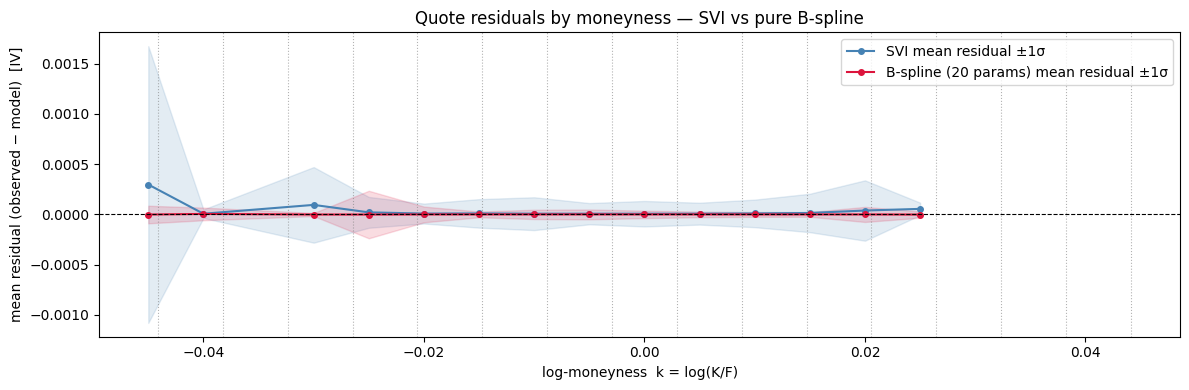

In [72]:
bin_w = 0.005


def _bin_residuals(df_quotes: pl.DataFrame, iv_col: str):
    df_clean = df_quotes.filter(
        pl.col("observed_iv").is_not_nan()
        & pl.col("observed_iv").is_not_null()
        & pl.col(iv_col).is_not_nan()
        & pl.col(iv_col).is_not_null()
        & pl.col("log_moneyness").is_not_nan()
    ).with_columns((pl.col("observed_iv") - pl.col(iv_col)).alias("residual"))
    return (
        df_clean.with_columns(
            ((pl.col("log_moneyness") / bin_w).round(0) * bin_w).alias("k_center")
        )
        .group_by("k_center")
        .agg(
            pl.col("residual").mean().alias("mean"),
            pl.col("residual").std().alias("std"),
            pl.col("residual").count().alias("n"),
        )
        .filter(pl.col("n") >= 100)
        .sort("k_center")
    )


agg_bs = _bin_residuals(df_quotes_bs, "bspline_iv")
agg_svi = _bin_residuals(df_quotes_svi, "spline_iv")

k_bs, mu_bs, sig_bs = (
    agg_bs["k_center"].to_numpy(),
    agg_bs["mean"].to_numpy(),
    agg_bs["std"].to_numpy(),
)
k_svi, mu_svi, sig_svi = (
    agg_svi["k_center"].to_numpy(),
    agg_svi["mean"].to_numpy(),
    agg_svi["std"].to_numpy(),
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.fill_between(k_svi, mu_svi - sig_svi, mu_svi + sig_svi, alpha=0.15, color="steelblue")
ax.plot(k_svi, mu_svi, "o-", color="steelblue", ms=4, lw=1.5, label="SVI mean residual ±1σ")

ax.fill_between(k_bs, mu_bs - sig_bs, mu_bs + sig_bs, alpha=0.15, color="crimson")
ax.plot(
    k_bs,
    mu_bs,
    "o-",
    color="crimson",
    ms=4,
    lw=1.5,
    label=f"B-spline ({N_BASIS} params) mean residual ±1σ",
)

for kk in bspline_interior_knots:
    ax.axvline(kk, color="grey", lw=0.8, ls=":", alpha=0.6)
ax.axhline(0, color="black", lw=0.8, ls="--")

ax.set_xlabel("log-moneyness  k = log(K/F)")
ax.set_ylabel("mean residual (observed − model)  [IV]")
ax.set_title("Quote residuals by moneyness — SVI vs pure B-spline")
ax.legend()
plt.tight_layout()
plt.show()

## Gatheral (2006) butterfly arbitrage check

For each timestamp reconstruct the total-variance smile
$w(k) = \hat{\text{IV}}(k)^2 \cdot T$
and evaluate the no-butterfly-arbitrage condition (Gatheral 2006):

$$g(k) = \left(1 - \frac{k\,w'}{2w}\right)^2
       - \frac{w'^2}{4}\!\left(\frac{1}{w} + \frac{1}{4}\right)
       + \frac{w''}{2} \geq 0 \quad \forall k$$

$g < 0$ at any $k$ signals a butterfly arbitrage.  The check is **fully vectorised**
across all timestamps.

In [73]:
# ── 1. Sub-sample states and align TTEs ───────────────────────────────────────
SUBSAMPLE = 1  # check every quote (set higher for speed)
idx = np.arange(0, len(df_state_bs), SUBSAMPLE)
df_arb = df_state_bs[idx]
tte_arr = df_quotes_bs[idx]["T"].to_numpy().astype(float)  # (n_rows,)
n_arb_rows = len(df_arb)

# ── 2. Extract beta matrix ────────────────────────────────────────────────────
beta_arb = np.column_stack(
    [df_arb[f"state_{j}"].to_numpy() for j in range(N_BASIS)]
)  # (n_rows, N_BASIS)

# ── 3. Dense k-grid — clipped to observed strike range ───────────────────────
N_K = 300
k_arb = np.linspace(k_min_obs, k_max_obs, N_K)
k_arb_cl = np.clip(k_arb, bspline_klo, bspline_khi)
B_arb = BSpline.design_matrix(k_arb_cl, bspline_knots, DEGREE).toarray()  # (N_K, N_BASIS)

# ── 4. Fitted IV and total variance ───────────────────────────────────────────
iv_arb = beta_arb @ B_arb.T  # (n_rows, N_K)
iv_arb = np.maximum(iv_arb, 1e-6)  # clip non-positive IV
T2d = tte_arr[:, np.newaxis]  # (n_rows, 1)
w_arb = iv_arb**2 * T2d  # total variance (n_rows, N_K)

print(f"States checked: {n_arb_rows:,}  |  k-grid: {N_K} pts  [{k_min_obs:.4f}, {k_max_obs:.4f}]")
print(f"w_arb shape   : {w_arb.shape}")

States checked: 978,523  |  k-grid: 300 pts  [-0.0465, 0.0241]
w_arb shape   : (978523, 300)


In [74]:
# ── 5. Gatheral g(k) — vectorised ─────────────────────────────────────────────
w_safe = np.maximum(w_arb, 1e-10)
k2d = k_arb[np.newaxis, :]

w1 = np.gradient(w_arb, k_arb, axis=1)  # dw/dk
w2 = np.gradient(w1, k_arb, axis=1)  # d²w/dk²

g = (
    (1.0 - k2d * w1 / (2.0 * w_safe)) ** 2 - (w1**2 / 4.0) * (1.0 / w_safe + 0.25) + w2 / 2.0
)  # (n_rows, N_K)

# ── Per-row k bounds from observed options ────────────────────────────────────
# Group by 1-second bucket so all strikes quoted within ~1 s of each other
# contribute to the observed k-range, capturing the forward drift intraday.
df_k_bounds = (
    df_quotes_bs.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("ts_sec"))
    .group_by("ts_sec")
    .agg(
        pl.col("log_moneyness").min().alias("k_min_t"),
        pl.col("log_moneyness").max().alias("k_max_t"),
    )
    .sort("ts_sec")
)

df_arb_bounds = df_arb.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("ts_sec")).join_asof(
    df_k_bounds, on="ts_sec", strategy="backward"
)
k_min_t = df_arb_bounds["k_min_t"].fill_null(k_min_obs).to_numpy().astype(float)
k_max_t = df_arb_bounds["k_max_t"].fill_null(k_max_obs).to_numpy().astype(float)

# Mask g to +inf outside the per-row observed k-range
in_range = (k_arb[np.newaxis, :] >= k_min_t[:, np.newaxis]) & (
    k_arb[np.newaxis, :] <= k_max_t[:, np.newaxis]
)
g_masked = np.where(in_range, g, np.inf)

min_g = g_masked.min(axis=1)
argmin_g = g_masked.argmin(axis=1)
is_arb = min_g < 0
n_bad = int(is_arb.sum())
pct_bad = is_arb.mean() * 100
worst = int(min_g.argmin())

print(f"Timestamps checked   : {n_arb_rows:,}")
print(f"Arbitrage-free       : {n_arb_rows - n_bad:,}  ({100 - pct_bad:.1f}%)")
print(f"Butterfly arbitrage  : {n_bad:,}  ({pct_bad:.1f}%)")
print(f"Min g (global worst) : {min_g.min():.5f}  at k={k_arb[argmin_g[worst]]:.4f}")
print(f"Mean min_g           : {min_g.mean():.5f}")

Timestamps checked   : 978,523
Arbitrage-free       : 835,840  (85.4%)
Butterfly arbitrage  : 142,683  (14.6%)
Min g (global worst) : -74.51068  at k=-0.0380
Mean min_g           : inf


In [75]:
g.shape

(978523, 300)

In [76]:
# # ── 6. g(k) curves at 6 representative timestamps ─────────────────────────────
# sample_idx = np.linspace(0, n_arb_rows - 1, 6, dtype=int)
# fig_g = go.Figure()
# for si in sample_idx:
#     si = int(si)
#     color = "crimson" if is_arb[si] else "steelblue"
#     label = (
#         f"{df_arb['ts_ns'][si].strftime('%H:%M:%S')}"
#         f"  {'[ARB]' if is_arb[si] else '[ok]'}"
#         f"  min_g={min_g[si]:.4f}"
#     )
#     fig_g.add_trace(
#         go.Scatter(
#             x=k_arb.tolist(),
#             y=g[si].tolist(),
#             mode="lines",
#             line=dict(width=1.5, color=color),
#             name=label,
#         )
#     )
# fig_g.add_hline(
#     y=0, line=dict(color="black", width=1.5, dash="dash"), annotation_text="g=0 arb threshold"
# )
# fig_g.update_layout(
#     title="Gatheral g(k) at representative timestamps  (red = butterfly arb)",
#     xaxis_title="log-moneyness  k",
#     yaxis_title="g(k)",
#     height=420,
#     legend=dict(x=1.01, y=1.0),
# )
# fig_g.show()

In [77]:
# # ── 7. Time series: min g(k, t) ───────────────────────────────────────────────
# ts_arb = df_arb["ts_ns"].to_list()

# fig_ts = make_subplots(
#     rows=2,
#     cols=1,
#     shared_xaxes=True,
#     row_heights=[0.65, 0.35],
#     vertical_spacing=0.06,
#     subplot_titles=["min g(k, t)  — Gatheral butterfly check", "Arbitrage flag"],
# )
# fig_ts.add_trace(
#     go.Scatter(
#         x=ts_arb,
#         y=min_g.tolist(),
#         mode="lines",
#         line=dict(color="steelblue", width=1),
#         name="min g(k)",
#     ),
#     row=1,
#     col=1,
# )
# fig_ts.add_trace(
#     go.Scatter(
#         x=ts_arb,
#         y=np.where(is_arb, min_g, np.nan).tolist(),
#         mode="markers",
#         marker=dict(color="crimson", size=3, opacity=0.5),
#         name="arb timestamps",
#     ),
#     row=1,
#     col=1,
# )
# fig_ts.add_hline(y=0, line=dict(color="red", width=1.5, dash="dash"), row=1, col=1)

# arb_flag = is_arb.astype(float)
# fig_ts.add_trace(
#     go.Scatter(
#         x=ts_arb,
#         y=arb_flag.tolist(),
#         mode="lines",
#         line=dict(color="crimson", width=1),
#         fill="tozeroy",
#         fillcolor="rgba(220,50,47,0.15)",
#         name="is_arb",
#     ),
#     row=2,
#     col=1,
# )

# fig_ts.update_layout(
#     title=f"Gatheral butterfly check — pure B-spline filter  ({pct_bad:.1f}% flagged)",
#     height=500,
#     legend=dict(x=1.01, y=1.0),
# )
# fig_ts.update_yaxes(title_text="min g(k)", row=1, col=1)
# fig_ts.update_yaxes(title_text="is_arb", tickvals=[0, 1], ticktext=["no", "yes"], row=2, col=1)
# fig_ts.update_xaxes(title_text="Time", row=2, col=1)
# fig_ts.show()